# RQ1 final charts: what the job market asks for, in resume order

Aileen (Py3onistas). This notebook makes the 7 charts we use in the slides and on the website, and saves a small summary table for each one in `data/summary/` so Jessy can load them in the app.

I go through the market the same way a resume is written:

1. Education: minimum degree, then majors
2. Experience: years by LinkedIn level, then years by industry and level
3. Skills by industry
4. Which job functions share postings (this leads into the recommendation part)
5. Salary by industry and state

Run `01_data_eda.ipynb` once before this one, so the text signals and the skill extraction are already cached in `data/processed/`.

If a posting doesn't say something (no degree, no years), I leave it out of that share. Not stated does not mean not required.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.data_processing import load_clean_jobs
from src.feature_extraction import extract_skills
from src.text_signals import add_text_signals, add_resume_signals
from src import market_analysis as ma
from src import industry_groups as ig
from src import rq1_charts as rc

PROCESSED = "../data/processed"
FIG = Path("../figures/final")
SUMMARY = Path("../data/summary")
FIG.mkdir(parents=True, exist_ok=True)
SUMMARY.mkdir(parents=True, exist_ok=True)

jobs = load_clean_jobs(f"{PROCESSED}/clean_jobs.parquet")
jobs = add_text_signals(jobs, cache_path=f"{PROCESSED}/text_signals.parquet")
jobs = add_resume_signals(jobs, cache_path=f"{PROCESSED}/resume_signals.parquet")
job_skills = ma.extract_skills_for_jobs(jobs, extract_skills, cache_path=f"{PROCESSED}/job_skills_extracted.parquet")
print(len(jobs), "postings")

119055 postings


## 0. Industry groups

LinkedIn gives 144 company industries in our data, and many of them are really the same field. "IT Services and IT Consulting" and "Software Development" are both CS/IT for a job seeker, and Banking, Insurance and Financial Services are all finance. My first version of the charts kept them apart and the rows looked strange, so I merge them into plain groups (the full list is in `src/industry_groups.py`).

A posting tagged with two names from the same group only counts once in that group. I check below that no LinkedIn name was missed.

In [2]:
jobs = ig.add_industry_group(jobs)
print("names not in any group:", ig.unmapped_industries(jobs))

ig.group_table().to_csv(SUMMARY / "industry_groups.csv", index=False)
jobs["industry"].explode().value_counts().head(20)

names not in any group: []


industry
CS/IT                              19261
Staffing and Recruiting            17978
Health care                        16183
Retail                             10745
Finance                             8656
Manufacturing                       7992
Hospitality, food and leisure       4721
Business, legal and HR services     3865
Media, marketing and arts           3415
Education                           3139
Pharma and biotech                  2968
Construction                        2873
Energy and utilities                2778
Non-profit and social services      2431
Transportation and logistics        2200
Government and public safety        1986
Real estate                         1829
Aerospace and defense               1630
Wholesale                           1341
Facilities and other services       1235
Name: count, dtype: int64

In [3]:
# I collect one sentence per chart here and save them all at the end
takeaways = []

## 1. Education

### 1.1 Minimum degree by industry

The degree I use is the lowest one the posting names, because that is what you need to apply. High school and associate degrees are merged into "Below bachelor". Staffing and recruiting firms are left out since they post jobs for other companies.

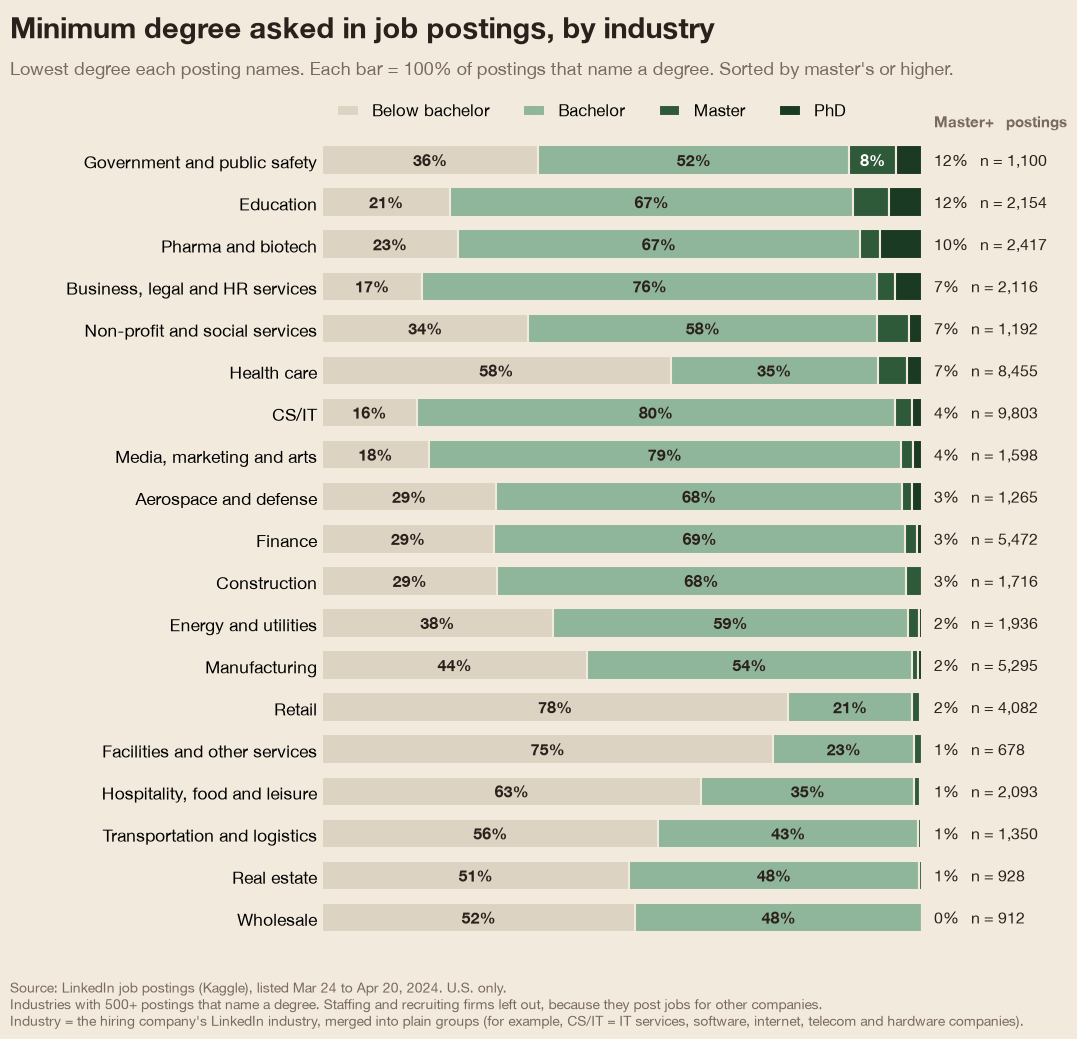

A bachelor's degree is the usual minimum, but Government and public safety asks for a master's or higher most often (12% of postings that name a degree), while Retail mostly asks for less than a bachelor's (78%).


In [4]:
degree = rc.minimum_degree(jobs, min_named=500)
degree.round(4).to_csv(SUMMARY / "rq1_min_degree_by_industry.csv")
rc.plot_minimum_degree(degree, FIG / "1_min_degree_by_industry.png")
plt.show()

most_master = degree["master_or_higher"].idxmax()
most_below = degree["Below bachelor"].idxmax()
sentence = (f"A bachelor's degree is the usual minimum, but {most_master} asks for a master's or higher most often "
            f"({degree.loc[most_master, 'master_or_higher']:.0%} of postings that name a degree), while {most_below} "
            f"mostly asks for less than a bachelor's ({degree.loc[most_below, 'Below bachelor']:.0%}).")
takeaways.append(("1", "Minimum degree by industry", sentence))
print(sentence)

### 1.2 Majors by industry

Share of the postings that name a major. One posting can name more than one major, so a row can add up to more than 100%.

In [5]:
majors = rc.top_majors(jobs, n_industries=15, min_named=300)
majors.round(4).to_csv(SUMMARY / "rq1_majors_by_industry.csv", index=False)
rc.plot_majors(majors, FIG / "2_majors_by_industry.png")
plt.show()

first = majors[majors["rank"] == 1].head(3)
parts = [f"{r.industry} names {r.major} ({r.share:.0%})" for r in first.itertuples()]
sentence = "The most named major fits each field: " + ", ".join(parts) + "."
takeaways.append(("2", "Majors by industry", sentence))
print(sentence)

<Figure size 1400x1360 with 0 Axes>

The most named major fits each field: CS/IT names Computer Science (44%), Health care names Nursing (50%), Finance names Business (40%).


## 2. Experience

### 2.1 Years asked by LinkedIn level

I use the smallest number of years the posting says ("3-5 years" counts as 3). Only postings that give a number are used.

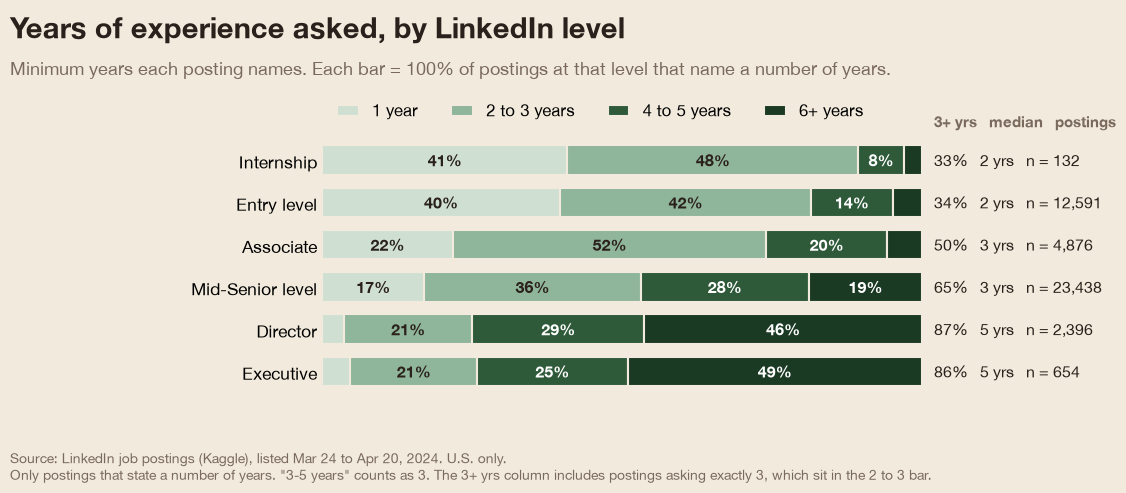

Even entry level postings ask for experience: 34% of the ones that give a number ask for 3 or more years, and the median is 2 years.


In [6]:
years = rc.years_by_level(jobs)
years.round(4).to_csv(SUMMARY / "rq1_years_by_level.csv")
rc.plot_years_by_level(years, FIG / "3_years_by_level.png")
plt.show()

entry = years.loc["Entry level"]
sentence = (f"Even entry level postings ask for experience: {entry['share_3plus']:.0%} of the ones that give a number "
            f"ask for 3 or more years, and the median is {entry['median_years']:g} years.")
takeaways.append(("3", "Years by level", sentence))
print(sentence)

### 2.2 Years by industry and level

Median years for each industry group and LinkedIn level. Cells with fewer than 50 postings say "too few". I dropped Internship and Executive because most groups have under 50 of those.

I also leave Retail out. In Retail, Mid-Senior jobs ask for fewer years (median 1) than Entry jobs (median 2), so the levels don't mean the same thing there and the row would be confusing. I print the Retail numbers here so this is easy to check.

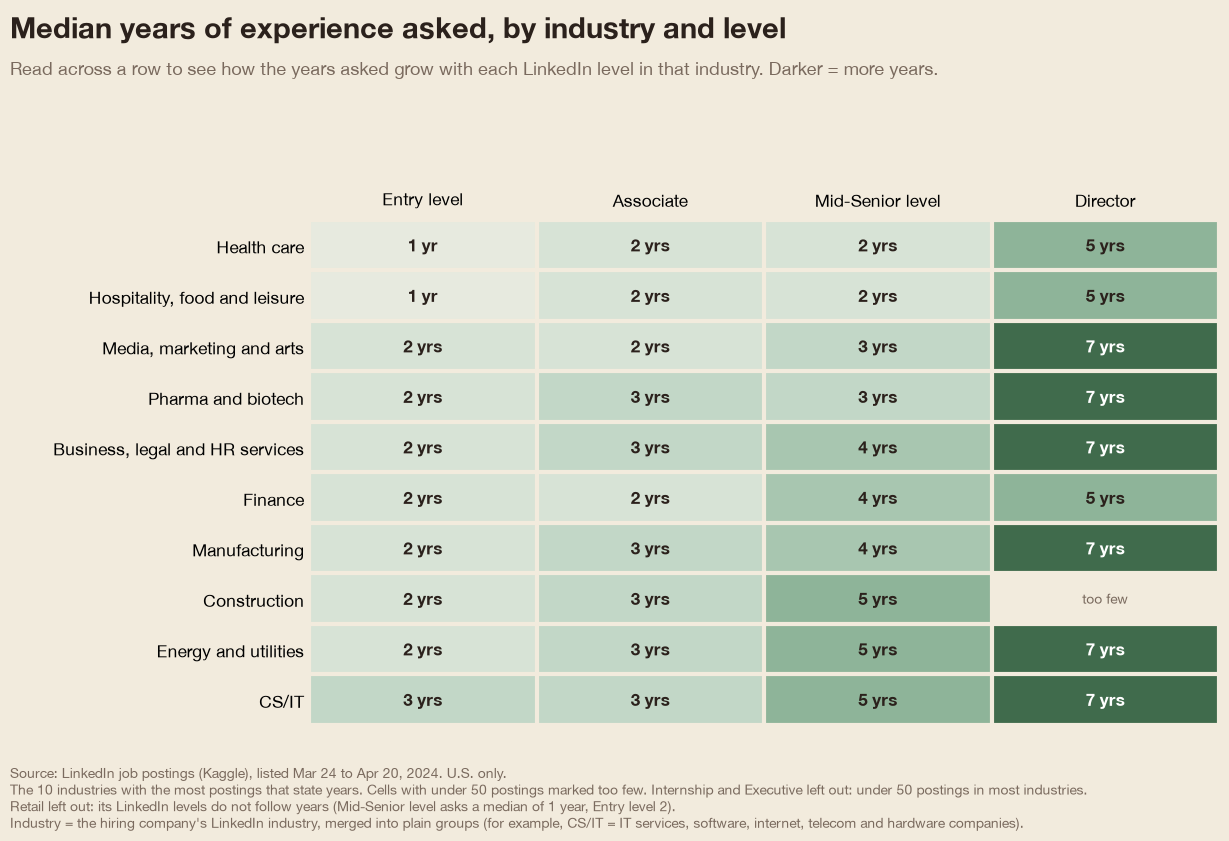

experience_level  Entry level  Associate  Mid-Senior level  Director
industry                                                            
Retail                    2.0        2.0               1.0       5.0
experience_level  Entry level  Associate  Mid-Senior level  Director
industry                                                            
Retail                    985        141              1469        51
Entry level jobs ask for a median of 1 to 3 years and Director jobs 5 to 7 years; CS/IT asks the most at entry level (3 years).


In [7]:
med, n = rc.years_grid(jobs, min_n=50)
med.join(n.add_prefix("n_")).to_csv(SUMMARY / "rq1_years_by_industry_level.csv")
rc.plot_years_grid(med, FIG / "4_years_by_industry_level.png")
plt.show()

# the Retail row I left out
retail, retail_n = rc.years_grid(jobs[jobs["industry"].apply(lambda v: "Retail" in v)], min_n=50, leave_out=())
print(retail.loc[["Retail"]], retail_n.loc[["Retail"]], sep="\n")

sentence = (f"Entry level jobs ask for a median of {med['Entry level'].min():g} to {med['Entry level'].max():g} years "
            f"and Director jobs {med['Director'].min():g} to {med['Director'].max():g} years; "
            f"{med['Entry level'].idxmax()} asks the most at entry level ({med['Entry level'].max():g} years).")
takeaways.append(("4", "Years by industry and level", sentence))
print(sentence)

## 3. Skills by industry

Share of each industry's postings that mention a skill from our fixed skill list (the extractor from `src/feature_extraction.py`). I only show skills named in at least 3% of postings, because in Retail most postings name none of our skills and the 3rd and 4th ones were around 1%.

In [8]:
skills = rc.top_skills(jobs, job_skills, n_industries=10, min_share=0.03)
skills.round(4).to_csv(SUMMARY / "rq1_skills_by_industry.csv", index=False)
rc.plot_skills(skills, FIG / "5_skills_by_industry.png")
plt.show()

first = skills[skills["rank"] == 1].head(2)
parts = [f"{r.industry} asks for {r.skill} ({r.share:.0%})" for r in first.itertuples()]
sentence = "Each field has its own top skill: " + " and ".join(parts) + "."
takeaways.append(("5", "Skills by industry", sentence))
print(sentence)

<Figure size 1400x1000 with 0 Axes>

Each field has its own top skill: CS/IT asks for Agile (14%) and Health care asks for Patient Care (41%).


## 4. Job functions that share postings

LinkedIn can give one posting more than one job function. If two functions are often on the same posting, the job mixes both kinds of work, so someone in one of them could look at the other. This is where my part hands over to the recommendation part.

Overlap = postings with both labels / postings of the smaller function. I only keep functions with 1,000+ postings and pairs of 50%+.

I leave out Management + Manufacturing. Almost every Manufacturing posting also has the Management tag, so that pair is about how LinkedIn tags jobs, not about real work.

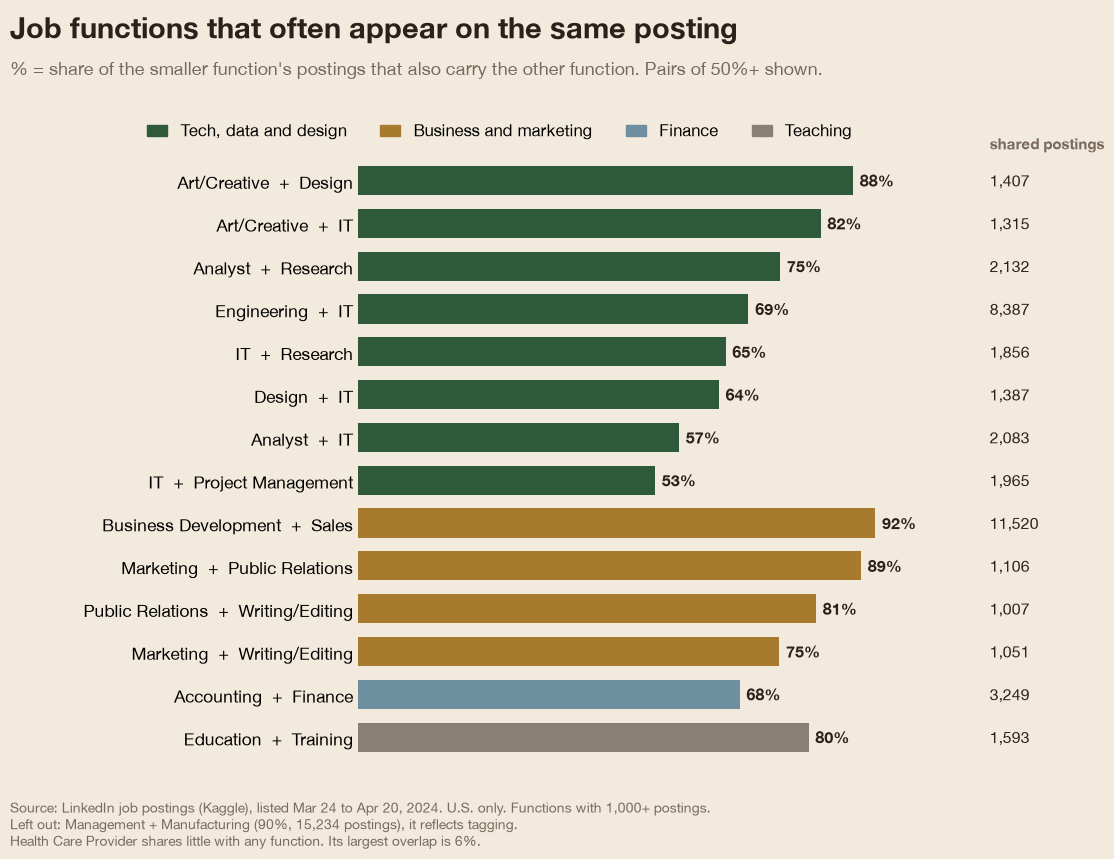

Close job functions often share postings, for example Business Development and Sales (92%), so a person in one may be able to apply to the other.


In [9]:
pairs = rc.function_pairs(jobs, min_postings=1000)
pairs.round(4).to_csv(SUMMARY / "rq1_function_pairs.csv", index=False)
strong = rc.strong_pairs(pairs, min_overlap=0.5)

mm = pairs[(pairs["function_a"].isin(["Management", "Manufacturing"])) & (pairs["function_b"].isin(["Management", "Manufacturing"]))]
health = pairs[(pairs["function_a"] == "Health Care Provider") | (pairs["function_b"] == "Health Care Provider")]
note = ""
if len(mm):
    note += f"Left out: Management + Manufacturing ({mm['overlap'].iloc[0]:.0%}, {mm['shared_postings'].iloc[0]:,} postings), it reflects tagging.\n"
if len(health):
    note += f"Health Care Provider shares little with any function. Its largest overlap is {health['overlap'].max():.0%}."
rc.plot_pairs(strong, note, FIG / "6_functions_on_same_posting.png")
plt.show()

if len(strong):
    top = strong.sort_values("overlap", ascending=False).iloc[0]
    sentence = (f"Close job functions often share postings, for example {top['function_a']} and {top['function_b']} "
                f"({top['overlap']:.0%}), so a person in one may be able to apply to the other.")
    takeaways.append(("6", "Functions on the same posting", sentence))
    print(sentence)

## 5. Salary by industry and state

Median of the salaries written in postings. Full-time jobs with a yearly salary between \$10,000 and \$1,000,000 only. This is not the legal minimum wage, it is just what companies posted.

Rows are the 5 industry groups with the most postings and columns are the 6 states with the most salary postings. Cells under 50 postings say "too few". I tried 10 states first, but NJ, PA, MA and IL were mostly too few.

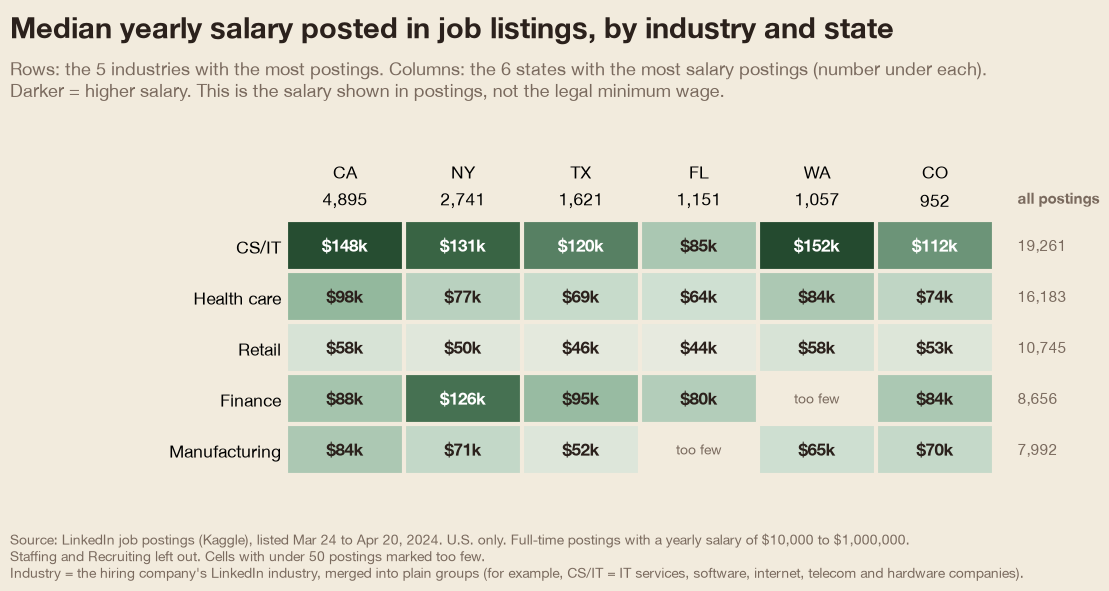

Industry changes posted pay more than state does: CS/IT pays $85k to $152k in these states, while Retail pays $44k to $58k.


In [10]:
sal, sal_n, states, sizes = rc.salary_grid(jobs, n_industries=5, n_states=6, min_n=50)
sal.join(sal_n.add_prefix("n_")).to_csv(SUMMARY / "rq1_salary_by_industry_state.csv")
rc.plot_salary_grid(sal, states, sizes, FIG / "7_salary_by_industry_state.png")
plt.show()

row_mid = sal.median(axis=1)
hi, lo = row_mid.idxmax(), row_mid.idxmin()
sentence = (f"Industry changes posted pay more than state does: {hi} pays ${sal.loc[hi].min()/1000:.0f}k to "
            f"${sal.loc[hi].max()/1000:.0f}k in these states, while {lo} pays ${sal.loc[lo].min()/1000:.0f}k to "
            f"${sal.loc[lo].max()/1000:.0f}k.")
takeaways.append(("7", "Salary by industry and state", sentence))
print(sentence)

## Takeaways

One sentence per chart, saved for the slides and the website.

In [11]:
takeaways = pd.DataFrame(takeaways, columns=["chart", "title", "takeaway"])
takeaways.to_csv(SUMMARY / "rq1_takeaways.csv", index=False)
for t in takeaways.itertuples():
    print(f"{t.chart}. {t.title}: {t.takeaway}")

1. Minimum degree by industry: A bachelor's degree is the usual minimum, but Government and public safety asks for a master's or higher most often (12% of postings that name a degree), while Retail mostly asks for less than a bachelor's (78%).
2. Majors by industry: The most named major fits each field: CS/IT names Computer Science (44%), Health care names Nursing (50%), Finance names Business (40%).
3. Years by level: Even entry level postings ask for experience: 34% of the ones that give a number ask for 3 or more years, and the median is 2 years.
4. Years by industry and level: Entry level jobs ask for a median of 1 to 3 years and Director jobs 5 to 7 years; CS/IT asks the most at entry level (3 years).
5. Skills by industry: Each field has its own top skill: CS/IT asks for Agile (14%) and Health care asks for Patient Care (41%).
6. Functions on the same posting: Close job functions often share postings, for example Business Development and Sales (92%), so a person in one may be abl